# 04 Extreme Frequency Model Spread Plots

In [10]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap, BoundaryNorm, Normalize

from cdrmip_extremes import (
    utils, stats, io_disk, plotting
)
from cdrmip_extremes.configs import CDR_MODELS, PROC_DIR, FIG_DIR

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
base = PROC_DIR / 'CDRMIP' / 'extremes'
varname = 'tas'

ext_data = {
    name: io_disk.load_nested(base / name, f"{varname}_{name}", order=CDR_MODELS)
    for name in ['exceedances_median_multimodel',
                 'branch_differences_median_multimodel',
                 'agreement']
}

In [4]:
exceedances = ext_data['exceedances_median_multimodel']
differences = ext_data['branch_differences_median_multimodel']
agreement = ext_data['agreement']

### Calculate standard deviation ###

In [6]:
expt='1pctCO2-cdr'

In [7]:
heat_freq_all = xr.concat(
    [
        differences[model][expt]['heat'] for model in differences.keys() if model != 'multi_model_median'
    ],
    dim='model',
    compat='override',
    coords='minimal'
)
cold_freq_all = xr.concat(
    [
        differences[model][expt]['cold'] for model in differences.keys() if model != 'multi_model_median'
    ],
    dim='model',
    compat='override',
    coords='minimal'
)
# Calculate std_dev
heat_freq_std_dev = heat_freq_all.std(dim='model')
cold_freq_std_dev = cold_freq_all.std(dim='model')

In [8]:
def add_colorbar(axes,norm,cmap,label,extend=False,custom_ticks=False,custom_labels=False):
    # Colorbar for `norm2` across the last column
    cbar_ax = fig.add_axes(axes)  # [left, bottom, width, height]
    cbar = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap), 
        cax=cbar_ax, 
        orientation='vertical',
        label=label,
        extend=extend,
        pad=0.02
    )
    if custom_ticks:
        cbar.set_ticks(custom_ticks)
        cbar.ax.set_yticklabels(custom_labels)
        cbar.ax.tick_params(labelsize=10)  # Adjust tick label size
    cbar.set_label(label,fontsize=12)
    return cbar_ax, cbar

## Plot ##

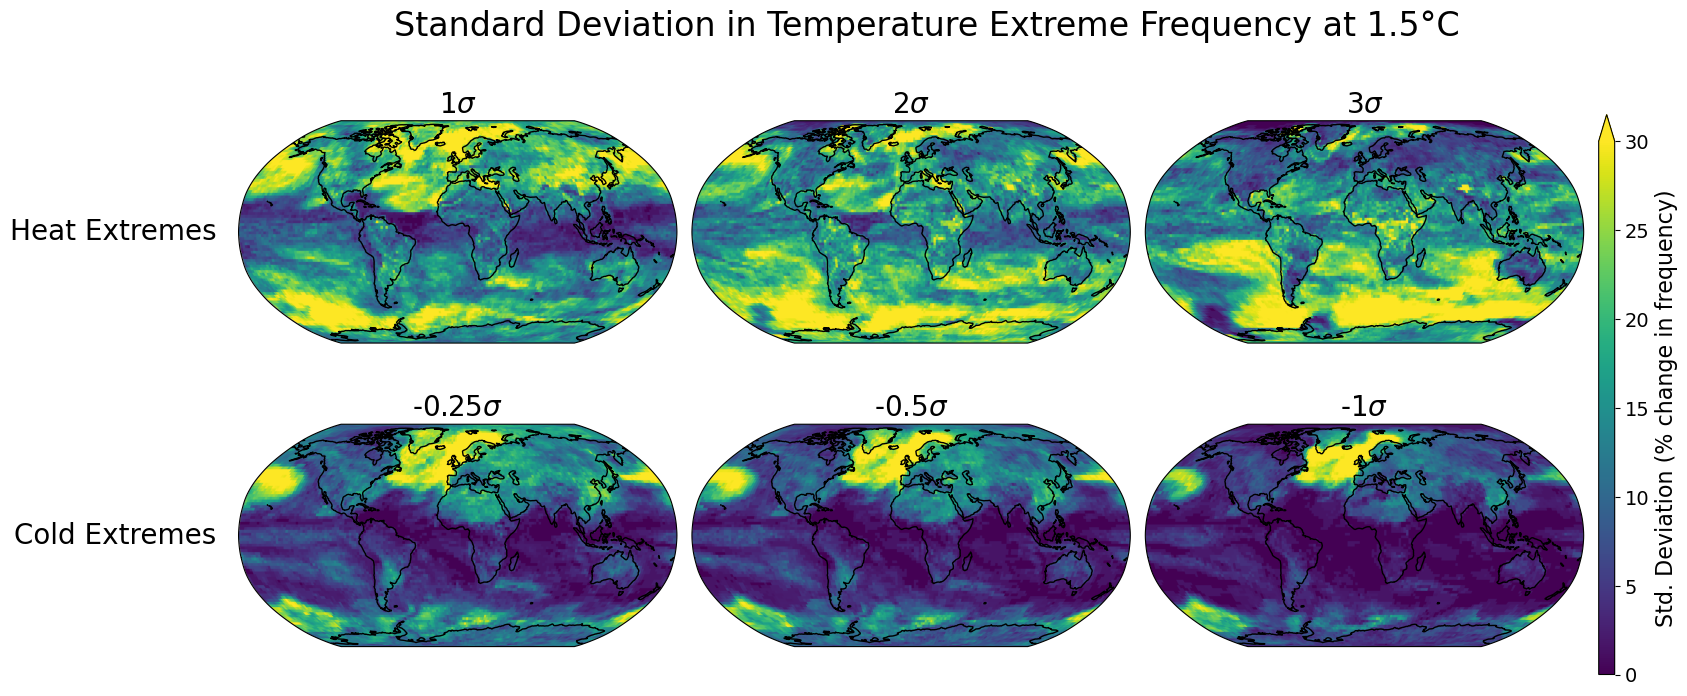

In [11]:
to_plot = {}
thresholds = ['sigma1','sigma2','sigma3']
threshold_symbs1 = ['1$\sigma$','2$\sigma$','3$\sigma$']
threshold_symbs2 = ['-0.25$\sigma$','-0.5$\sigma$','-1$\sigma$']
gwl=1.5
exceedance_heat = heat_freq_std_dev
exceedance_cold = cold_freq_std_dev
data = [('heat',exceedance_heat),('cold',exceedance_cold)]
for ext_type, exceedance in data:
    differences = {}
    for threshold in thresholds:
        std_dev = exceedance[threshold].sel(gwl=gwl)
        differences[threshold] = std_dev
    to_plot[ext_type] = differences

fig, axes = plt.subplots(2,
                         3,
                         subplot_kw={"projection":ccrs.Robinson()},
                         figsize=(16,7),
                         sharey=True,
                        )
cbar_kwargs_diff = {"fraction": 0.06, "aspect": 20,
                "label":"Change in %",'orientation':'horizontal',
                'location':'bottom','pad':0.05,
               } 


for row_index, ext_type in enumerate(to_plot.keys()):
    if ext_type == 'heat':
        threshold_symbs=threshold_symbs1
    else:

        threshold_symbs=threshold_symbs2
    for col_index, threshold in enumerate(to_plot[ext_type].keys()):
        ax = axes[row_index,col_index]
        im = ax.imshow(to_plot[ext_type][threshold],
                       transform=ccrs.PlateCarree(),
                       cmap='viridis',
                       origin='lower',
                       extent=(0,360,-90,90),
                       vmin=0,
                       vmax=30
                      )
        ax.coastlines()
        ax.set_title(f"{threshold_symbs[col_index]}",fontsize=20)


norm1 = Normalize(vmin=0, vmax=30)  # For heat extremes
norm2 = Normalize(vmin=0, vmax=30)  # For cold extremes

cbar_ax2, cbar2 = add_colorbar([1.0,0.05,0.01,0.8],
                               norm2,
                               'viridis',
                              "Std. Deviation (% change in frequency)",
                               extend = 'max',
                               # custom_ticks = [-30, -20, -10, 0, 10, 20, 30],
                               # custom_labels = ['-30%', '-20%', '-10%', '0', '10%', '20%', '30%'],
                              )
cbar2.set_label("Std. Deviation (% change in frequency)", fontsize=16)
cbar2.ax.tick_params(labelsize=14)


axes[0][0].annotate('Heat Extremes',
                    xy = (-0.05,0.5),
                    xycoords="axes fraction",
                    ha='right',
                    va='center',
                    fontsize=20,
                    rotation=0
                   )
axes[1][0].annotate('Cold Extremes',
                    xy = (-0.05,0.5),
                    xycoords="axes fraction",
                    ha='right',
                    va='center',
                    fontsize=20,
                    rotation=0
                   )
fig.suptitle(f'Standard Deviation in Temperature Extreme Frequency at {gwl}°C',x=0.58,y=1.0,fontsize=24)
fig.tight_layout()
plt.show()

In [12]:
fig.savefig(
    FIG_DIR / "main" / "figure_6.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

## Statistics

In [12]:
for sigma in ['sigma1', 'sigma2', 'sigma3']:
    da = heat_freq_std_dev.sel(gwl=1.5)[sigma]
    max_heat = da.max().values

    idx = da.argmax(dim=['lat', 'lon'])   # {'lat': <int index>, 'lon': <int index>}
    max_lat = da.lat.isel(lat=idx['lat']).values
    max_lon = da.lon.isel(lon=idx['lon']).values

    print(sigma)
    print(f"Max: {max_heat}")
    print(f"Max location: lat={max_lat}, lon={max_lon}")

sigma1
Max: 48.25468618931248
Max location: lat=71.0, lon=358.0
sigma2
Max: 44.607128559988546
Max location: lat=71.0, lon=348.0
sigma3
Max: 41.40650068913972
Max location: lat=-63.0, lon=354.0


In [16]:
for sigma in ['sigma1', 'sigma2', 'sigma3']:
    da = cold_freq_std_dev.sel(gwl=1.5)[sigma]
    max_heat = da.max().values

    idx = da.argmax(dim=['lat', 'lon'])   # {'lat': <int index>, 'lon': <int index>}
    max_lat = da.lat.isel(lat=idx['lat']).values
    max_lon = da.lon.isel(lon=idx['lon']).values

    print(sigma)
    print(f"Max: {max_heat}")
    print(f"Max location: lat={max_lat}, lon={max_lon}")

sigma1
Max: 42.45429047864717
Max location: lat=73.0, lon=36.0
sigma2
Max: 42.58761144424605
Max location: lat=65.0, lon=350.0
sigma3
Max: 40.820489441904584
Max location: lat=57.0, lon=352.0
